<a href="https://colab.research.google.com/github/Narin-dlwlrma/Artificial-Intelligence-TP/blob/master/TP3_PHET_Narin_e20230091_I4_AMSB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---


**Name:** PHET NARIN

**Student ID:** e20230091

**Class:** I4-AMS-B

---




# TP3: Initialization and Regularization

**How this notebook works**
1. **Follow along (Parts 0–2).** We go through the notebook together.
2. **Assignment (at the end).** On your own: 8 exercises, to be submitted.

| Part | Topic | Lecture 3 slides |
|---|---|---|
| 0 | Setup and helper functions | |
| 1 | Initialization: zeros, large random, He; then `nn.init` | Initialization of Parameters · Vanishing and exploding gradients · Weight initialization for deep networks |
| 2 | Regularization: L2 and dropout; then `weight_decay` and `nn.Dropout` | L2 regularization: neural network · Dropout regularization · Why does dropout work? |
| ★ | Assignment: moons, Tanh, spirals, regularization | |

**Notation:** $\mathbf{X}$ has shape $(m, n^{[0]})$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, $\mathbf{b}^{[l]}$ has shape $(1, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$. Labels $\mathbf{Y}$ have shape $(m, 1)$.

## 0 · Setup and helper functions

In [ ]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


Three helpers used everywhere:
- `accuracy_fn(y_true, y_pred)`: the percentage of correct predictions.
- `accuracy(model, X, y)`: runs a model that outputs **logits** in evaluation mode and returns its accuracy. A "model" can be an `nn.Module` or any function, such as our hand-written network.
- `plot_decision_boundary(model, X, y)`: colors the plane by the predicted class. It works for binary models (one logit) and multi-class models (one logit per class), like the helper of Bourke's notebook.

In [ ]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return correct / len(y_pred) * 100

def predict_labels(logits):
    # binary: one logit -> sigmoid -> round; multi-class: argmax over the classes
    if logits.shape[1] == 1:
        return torch.round(torch.sigmoid(logits))
    return logits.argmax(dim=1)

def accuracy(model, X, y):
    if isinstance(model, nn.Module):
        model.eval()
        X, y = X.to(device), y.to(device)
    with torch.inference_mode():
        return accuracy_fn(y, predict_labels(model(X)))

def plot_decision_boundary(model, X, y, lim=None):
    X, y = X.cpu(), y.cpu()
    lo, hi = (X.min() - 0.2, X.max() + 0.2) if lim is None else (-lim, lim)
    xx, yy = torch.meshgrid(torch.linspace(lo, hi, 300), torch.linspace(lo, hi, 300), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    if isinstance(model, nn.Module):
        model.eval(); grid = grid.to(device)
    with torch.inference_mode():
        Z = predict_labels(model(grid)).reshape(300, 300).cpu()
    plt.contourf(xx, yy, Z, alpha=0.6, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
    plt.xlim(lo, hi); plt.ylim(lo, hi)

**The 3-layer network, by hand.** LINEAR → ReLU → LINEAR → ReLU → LINEAR → sigmoid. You know every line from Lecture 2 and the follow-along; here it is written out for exactly three layers, so that we can modify it in Part 2.

In [ ]:
def compute_cost(A3, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples.
    A3 = A3.clamp(eps, 1 - eps)
    return -(Y * torch.log(A3) + (1 - Y) * torch.log(1 - A3)).mean()

def forward_propagation(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, A1, Z2, A2, Z3, A3)
    return A3, cache

def backward_propagation(X, Y, params, cache):
    m = X.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def update_parameters(params, grads, lr):
    return {k: params[k] - lr * grads["d" + k] for k in params}

def logits_by_hand(params):
    # turns a dictionary of parameters into a "model": X -> Z3 (logits)
    return lambda X: forward_propagation(X, params)[1][4]

def plot_costs(costs, title, every):
    plt.figure(figsize=(5, 3))
    plt.plot([every * i for i in range(len(costs))], costs)
    plt.xlabel("iteration"); plt.ylabel("cost"); plt.title(title); plt.grid(alpha=0.3); plt.show()

## 1 · Initialization

### 1.1 The data
Two circles, one inside the other: 300 training points and 100 test points with 2 features. No straight line separates them, so the network needs its hidden layers.

In [ ]:
def load_circles():
    Xtr, ytr = make_circles(n_samples=300, noise=0.05, random_state=1)
    Xte, yte = make_circles(n_samples=100, noise=0.05, random_state=2)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(Xtr), to_t(ytr).reshape(-1, 1), to_t(Xte), to_t(yte).reshape(-1, 1)

train_X (300, 2) | train_Y (300, 1) | test_X (100, 2)


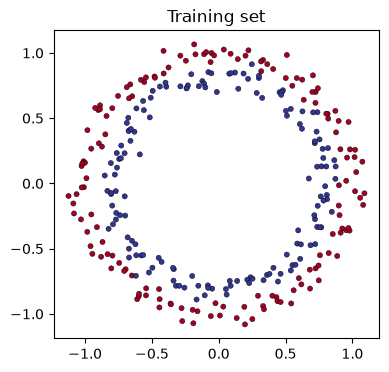

In [ ]:
train_X, train_Y, test_X, test_Y = load_circles()
print("train_X", tuple(train_X.shape), "| train_Y", tuple(train_Y.shape), "| test_X", tuple(test_X.shape))
plt.figure(figsize=(4.2, 4))
plt.scatter(train_X[:, 0], train_X[:, 1], c=train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 1.2 The model, by hand
`model` trains the 3-layer network `[2, 10, 5, 1]` with batch gradient descent. The only thing that changes between experiments is the **initialization**: `"zeros"`, `"random"` or `"he"`. The three functions are defined just after.

In [ ]:
def model(X, Y, initialization="he", lr=0.01, num_iters=15000, print_every=100):
    layer_dims = [X.shape[1], 10, 5, 1]
    if initialization == "zeros":
        params = initialize_parameters_zeros(layer_dims)
    elif initialization == "random":
        params = initialize_parameters_random(layer_dims)
    elif initialization == "he":
        params = initialize_parameters_he(layer_dims)
    costs = []
    for i in range(num_iters):
        A3, cache = forward_propagation(X, params)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(X, Y, params, cache)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            costs.append(cost.item())
            if i % (5 * print_every) == 0:
                print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

def show(params, costs, title):
    print(f"train accuracy {accuracy(logits_by_hand(params), train_X, train_Y):.1f}% | "
          f"test accuracy {accuracy(logits_by_hand(params), test_X, test_Y):.1f}%")
    plot_costs(costs, title, 1000)
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(logits_by_hand(params), train_X, train_Y, lim=1.5); plt.show()

### 1.3 Zero initialization
All weights and biases start at 0. Shapes: $\mathbf{W}^{[l]}$ is $(n^{[l-1]}, n^{[l]})$ and $\mathbf{b}^{[l]}$ is $(1, n^{[l]})$.

In [ ]:
def initialize_parameters_zeros(layer_dims):
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.zeros(layer_dims[l - 1], layer_dims[l])
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

for k, v in initialize_parameters_zeros([3, 2, 1]).items():
    print(k, "=", v.tolist())

W1 = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
b1 = [[0.0, 0.0]]
W2 = [[0.0], [0.0]]
b2 = [[0.0]]


In [ ]:
params_zeros, costs_zeros = model(train_X, train_Y, initialization="zeros")

Cost after iteration 0: 0.6931
Cost after iteration 500: 0.6931
Cost after iteration 1000: 0.6931
Cost after iteration 1500: 0.6931
Cost after iteration 2000: 0.6931
Cost after iteration 2500: 0.6931
Cost after iteration 3000: 0.6931
Cost after iteration 3500: 0.6931
Cost after iteration 4000: 0.6931
Cost after iteration 4500: 0.6931
Cost after iteration 5000: 0.6931
Cost after iteration 5500: 0.6931
Cost after iteration 6000: 0.6931
Cost after iteration 6500: 0.6931
Cost after iteration 7000: 0.6931
Cost after iteration 7500: 0.6931
Cost after iteration 8000: 0.6931
Cost after iteration 8500: 0.6931
Cost after iteration 9000: 0.6931
Cost after iteration 9500: 0.6931
Cost after iteration 10000: 0.6931
Cost after iteration 10500: 0.6931
Cost after iteration 11000: 0.6931
Cost after iteration 11500: 0.6931
Cost after iteration 12000: 0.6931
Cost after iteration 12500: 0.6931
Cost after iteration 13000: 0.6931
Cost after iteration 13500: 0.6931
Cost after iteration 14000: 0.6931
Cost afte

train accuracy 50.0% | test accuracy 50.0%


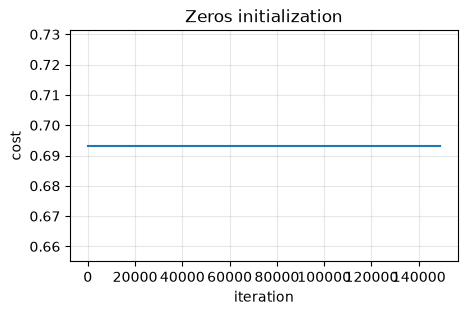

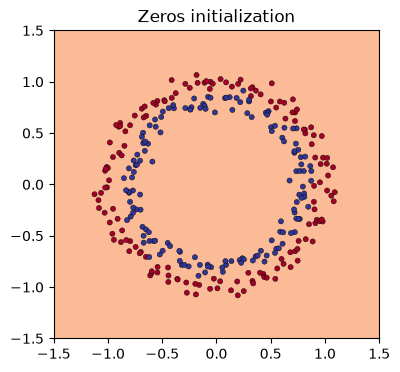

In [ ]:
show(params_zeros, costs_zeros, "Zeros initialization")

The cost never moves from $\log 2 = 0.6931$, and the model predicts the same class for every point: 50% accuracy.

**Why?** With all weights 0, every $\mathbf{Z}^{[l]}$ is 0, every ReLU outputs 0, and the sigmoid outputs $\sigma(0) = 0.5$ for every example. The gradients of $\mathbf{W}^{[2]}$ and $\mathbf{W}^{[3]}$ are products with activations that are all 0, and the error sent back through $\mathbf{W}^{[3]} = \mathbf{0}$ is 0: only $b^{[3]}$ could move, and it stays at 0 because the two classes are balanced. More generally, units that start equal compute the same thing and get the same update forever: the network cannot **break the symmetry**.

**Remember:** initialize $\mathbf{W}^{[l]}$ randomly. The biases $\mathbf{b}^{[l]}$ can start at 0.

### 1.4 Large random initialization
Random weights break the symmetry. Here we try **large** ones: `torch.randn(...) * 10`.

In [ ]:
def initialize_parameters_random(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * 10
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [ ]:
params_random, costs_random = model(train_X, train_Y, initialization="random")

Cost after iteration 0: 7.1061
Cost after iteration 500: 0.4967
Cost after iteration 1000: 0.3922
Cost after iteration 1500: 0.3587
Cost after iteration 2000: 0.3151
Cost after iteration 2500: 0.3218
Cost after iteration 3000: 0.2938
Cost after iteration 3500: 0.3326
Cost after iteration 4000: 0.3208
Cost after iteration 4500: 0.3045
Cost after iteration 5000: 0.2632
Cost after iteration 5500: 0.2424
Cost after iteration 6000: 0.2336
Cost after iteration 6500: 0.2293
Cost after iteration 7000: 0.2251
Cost after iteration 7500: 0.2224
Cost after iteration 8000: 0.2729
Cost after iteration 8500: 0.2640
Cost after iteration 9000: 0.1911
Cost after iteration 9500: 0.2113
Cost after iteration 10000: 0.2219
Cost after iteration 10500: 0.2453
Cost after iteration 11000: 0.1960
Cost after iteration 11500: 0.1951
Cost after iteration 12000: 0.1934
Cost after iteration 12500: 0.1973
Cost after iteration 13000: 0.1945
Cost after iteration 13500: 0.1862
Cost after iteration 14000: 0.1884
Cost afte

train accuracy 94.3% | test accuracy 90.0%


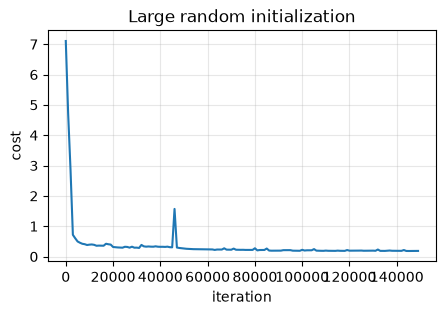

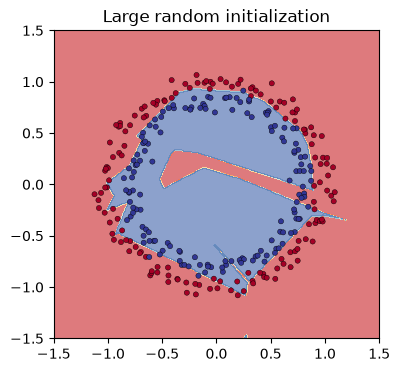

In [ ]:
show(params_random, costs_random, "Large random initialization")

The symmetry is broken and the model learns something, but slowly:

- The **first cost is very large.** With weights of size 10, $\mathbf{Z}^{[3]}$ is huge, the sigmoid outputs almost exactly 0 or 1, and every wrong prediction costs $-\log(\text{almost } 0)$. (Without the `clamp` in `compute_cost`, the cost would be `inf`.)
- Saturated outputs and huge activations make the optimization slow and unstable: the activations are close to **exploding**.

### 1.5 He initialization
For ReLU layers, He et al. (2015) scale the random weights by $\sqrt{2 / n^{[l-1]}}$ (lecture: "Weight initialization for deep networks").

In [ ]:
def initialize_parameters_he(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * (2 / layer_dims[l - 1]) ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [ ]:
params_he, costs_he = model(train_X, train_Y, initialization="he")

Cost after iteration 0: 0.7258
Cost after iteration 500: 0.6867
Cost after iteration 1000: 0.6828
Cost after iteration 1500: 0.6795
Cost after iteration 2000: 0.6759
Cost after iteration 2500: 0.6707
Cost after iteration 3000: 0.6642
Cost after iteration 3500: 0.6563
Cost after iteration 4000: 0.6454
Cost after iteration 4500: 0.6322
Cost after iteration 5000: 0.6168
Cost after iteration 5500: 0.5978
Cost after iteration 6000: 0.5745
Cost after iteration 6500: 0.5488
Cost after iteration 7000: 0.5179
Cost after iteration 7500: 0.4846
Cost after iteration 8000: 0.4455
Cost after iteration 8500: 0.4060
Cost after iteration 9000: 0.3544
Cost after iteration 9500: 0.3080
Cost after iteration 10000: 0.2687
Cost after iteration 10500: 0.2371
Cost after iteration 11000: 0.2109
Cost after iteration 11500: 0.1892
Cost after iteration 12000: 0.1709
Cost after iteration 12500: 0.1558
Cost after iteration 13000: 0.1431
Cost after iteration 13500: 0.1327
Cost after iteration 14000: 0.1240
Cost afte

train accuracy 97.7% | test accuracy 94.0%


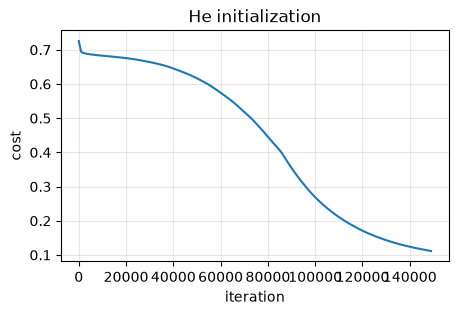

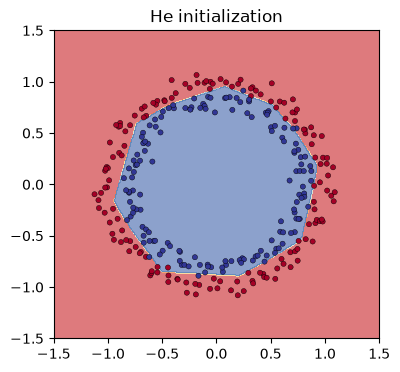

In [ ]:
show(params_he, costs_he, "He initialization")

### 1.6 Using PyTorch

| By hand | `torch.nn` |
|---|---|
| `torch.zeros(n_prev, n_l)` | `nn.init.zeros_(layer.weight)` |
| `torch.randn(n_prev, n_l) * 10` | `nn.init.normal_(layer.weight, mean=0.0, std=10.0)` |
| `torch.randn(n_prev, n_l) * (2 / n_prev) ** 0.5` | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` |
| `torch.zeros(1, n_l)` | `nn.init.zeros_(layer.bias)` |

**One difference to remember:** `nn.Linear` stores its weight as `(n_out, n_in)`, the transpose of our $\mathbf{W}^{[l]}$, and computes `X @ weight.T + bias`. "Kaiming" is He's first name; by default it uses `n_in` (the "fan-in"), as in the lecture.

In [ ]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=5)
        self.layer_3 = nn.Linear(in_features=5, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def init_weights(model, method, seed=3):
    torch.manual_seed(seed)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            if method == "zeros":
                nn.init.zeros_(layer.weight)
            elif method == "random":
                nn.init.normal_(layer.weight, mean=0.0, std=10.0)
            elif method == "he":
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model

model_0 = init_weights(CircleModel(), "he").to(device)
print(model_0)
print("layer_1.weight:", tuple(model_0.layer_1.weight.shape), "= (n_out, n_in) | std",
      round(model_0.layer_1.weight.std().item(), 3), "| sqrt(2 / n_in) =", round((2 / 2) ** 0.5, 3))

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=5, bias=True)
  (layer_3): Linear(in_features=5, out_features=1, bias=True)
  (relu): ReLU()
)
layer_1.weight: (10, 2) = (n_out, n_in) | std 0.676 | sqrt(2 / n_in) = 1.0


In [ ]:
check_model = CircleModel()
p = initialize_parameters_he([2, 10, 5, 1])
with torch.no_grad():
    for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
        layer.weight.copy_(p[f"W{l}"].T)          # (n_in, n_out) -> (n_out, n_in)
        layer.bias.copy_(p[f"b{l}"].flatten())

A3_hand, cache = forward_propagation(train_X, p)
grads = backward_propagation(train_X, train_Y, p, cache)
loss = nn.BCEWithLogitsLoss()(check_model(train_X), train_Y)
loss.backward()                                    # autograd

print(f"sigmoid(logits) vs A3: max difference {(torch.sigmoid(check_model(train_X)) - A3_hand).abs().max().item():.1e}")
for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
    print(f"dW{l}: max difference {(layer.weight.grad.T - grads[f'dW{l}']).abs().max().item():.1e} | "
          f"db{l}: max difference {(layer.bias.grad - grads[f'db{l}'].flatten()).abs().max().item():.1e}")

sigmoid(logits) vs A3: max difference 0.0e+00
dW1: max difference 7.5e-09 | db1: max difference 3.7e-09
dW2: max difference 3.0e-08 | db2: max difference 3.7e-09
dW3: max difference 1.9e-09 | db3: max difference 0.0e+00


In [ ]:
def train_and_test(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        y_logits = model(X_train)                       # 1. forward pass (logits)
        y_pred = torch.round(torch.sigmoid(y_logits))   #    logits -> probabilities -> labels
        loss = loss_fn(y_logits, y_train)               # 2. loss
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad()                           # 3. zero the gradients
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. gradient descent step

        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

In [ ]:
torch.manual_seed(42)
model_0 = init_weights(CircleModel(), "he").to(device)
loss_fn = nn.BCEWithLogitsLoss()                                 # sigmoid + binary cross-entropy
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
model_0 = train_and_test(model_0, loss_fn, optimizer, train_X, train_Y, test_X, test_Y, epochs=15000, print_every=3000)

Epoch:     0 | Loss: 0.69057, Accuracy: 50.00% | Test loss: 0.69148, Test acc: 50.00%
Epoch:  3000 | Loss: 0.63031, Accuracy: 64.33% | Test loss: 0.63650, Test acc: 63.00%
Epoch:  6000 | Loss: 0.41412, Accuracy: 93.33% | Test loss: 0.42873, Test acc: 94.00%
Epoch:  9000 | Loss: 0.18769, Accuracy: 97.33% | Test loss: 0.22121, Test acc: 94.00%
Epoch: 12000 | Loss: 0.11551, Accuracy: 98.33% | Test loss: 0.16742, Test acc: 93.00%


initialization      train     test
zeros               50.0%    50.0%
random              79.0%    76.0%
he                  98.7%    93.0%
default             97.3%    92.0%


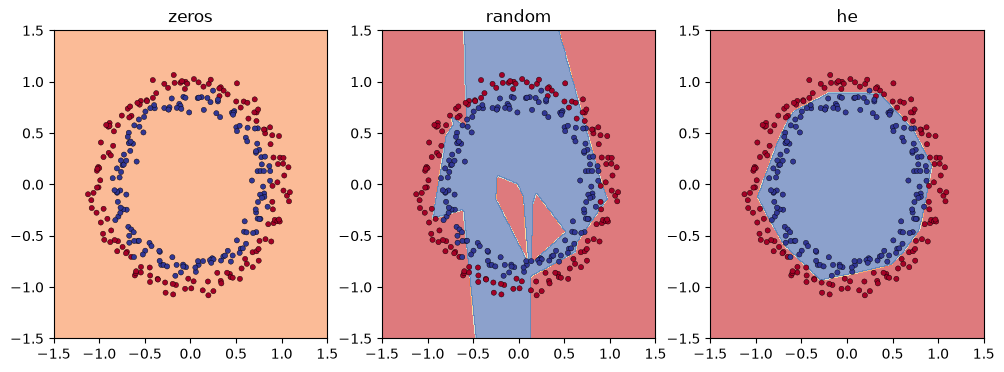

In [ ]:
results_init = {}
for method in ["zeros", "random", "he", "default"]:
    torch.manual_seed(3)
    m = CircleModel()                          # PyTorch's default initialization
    if method != "default":
        init_weights(m, method)
    m = m.to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    train_and_test(m, nn.BCEWithLogitsLoss(), opt, train_X, train_Y, test_X, test_Y, epochs=15000)
    results_init[method] = (accuracy(m, train_X, train_Y), accuracy(m, test_X, test_Y))

print(f"{'initialization':16s} {'train':>8s} {'test':>8s}")
for method, (tr, te) in results_init.items():
    print(f"{method:16s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(12, 4))
for k, method in enumerate(["zeros", "random", "he"]):
    torch.manual_seed(3)
    m = init_weights(CircleModel(), method).to(device)
    train_and_test(m, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.01), train_X, train_Y, test_X, test_Y, epochs=15000)
    plt.subplot(1, 3, k + 1); plt.title(method); plot_decision_boundary(m, train_X, train_Y, lim=1.5)
plt.show()

**What to remember from Part 1**
- Different initializations give very different results with the same network and the same training.
- Random weights break the symmetry; weights that are too large saturate the output and slow down learning.
- For ReLU networks, use He initialization: `nn.init.kaiming_normal_(w, nonlinearity="relu")`.

---
## 2 · Regularization

### 2.1 The data
A noisy 2-D dataset: 211 training points and 200 test points. The true boundary is a gentle curve, but the training labels contain mistakes: about 6% random errors, plus a few small **pockets** of wrong labels (for example, a region labeled by a careless annotator). The test labels contain only the random errors. A network that fits the pockets will generalize badly.

In [ ]:
def make_noisy_2d(m, seed, pockets=()):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, (m, 2))                                  # uniform in [-1, 1]^2
    Y = (X[:, 1] > 0.35 * np.sin(2.2 * X[:, 0]) - 0.1 * X[:, 0]).astype(float)
    flip = rng.random(m) < 0.06                                     # random label errors
    for cx, cy, r in pockets:                                       # pockets of wrong labels
        inside = (X[:, 0] - cx) ** 2 + (X[:, 1] - cy) ** 2 < r ** 2
        flip |= inside & (rng.random(m) < 0.7)
    Y[flip] = 1 - Y[flip]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

train (211, 2) | test (200, 2) | fraction of class 1: 0.5


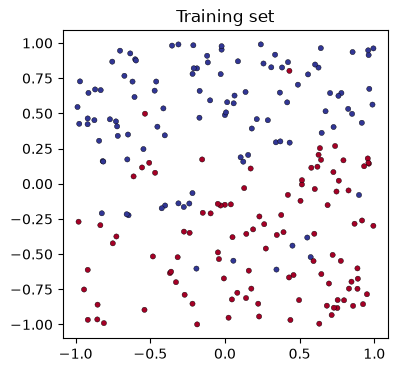

In [ ]:
POCKETS = [(-0.55, 0.05, 0.12), (0.1, 0.45, 0.10), (0.5, -0.45, 0.12), (-0.2, -0.55, 0.10)]
reg_train_X, reg_train_Y = make_noisy_2d(211, seed=0, pockets=POCKETS)
reg_test_X, reg_test_Y = make_noisy_2d(200, seed=1)
print("train", tuple(reg_train_X.shape), "| test", tuple(reg_test_X.shape), "| fraction of class 1:", round(reg_train_Y.mean().item(), 2))
plt.figure(figsize=(4.2, 4))
plt.scatter(reg_train_X[:, 0], reg_train_X[:, 1], c=reg_train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 2.2 The baseline model, by hand
The network is `[2, 20, 3, 1]`, initialized with $\sqrt{1/n^{[l-1]}}$ and trained for 30,000 iterations with $\alpha = 0.3$. `model_reg` can run in three modes:
- no regularization: `lambd = 0`, `keep_prob = 1`;
- **L2 regularization**: `lambd > 0` (we write `lambd` because `lambda` is a Python keyword);
- **dropout**: `keep_prob < 1`.

The L2 and dropout functions it calls are written in 2.3 and 2.4.

Cost after iteration 0: 0.7019
Cost after iteration 10000: 0.1380
Cost after iteration 20000: 0.0629
no regularization: train accuracy 96.7% | test accuracy 85.0%


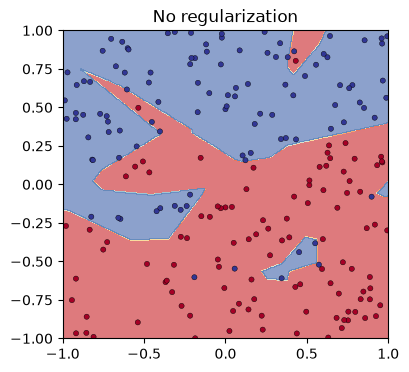

In [ ]:
def initialize_parameters(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) / layer_dims[l - 1] ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

def model_reg(X, Y, lr=0.3, num_iters=30000, lambd=0.0, keep_prob=1.0, print_every=10000, seed=1):
    params = initialize_parameters([X.shape[1], 20, 3, 1])
    gen = torch.Generator().manual_seed(seed)          # random masks for dropout
    for i in range(num_iters):
        if keep_prob == 1:
            A3, cache = forward_propagation(X, params)
        else:
            A3, cache = forward_propagation_with_dropout(X, params, keep_prob, gen)
        if lambd == 0:
            cost = compute_cost(A3, Y)
        else:
            cost = compute_cost_with_regularization(A3, Y, params, lambd)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, params, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, params, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, params, cache, keep_prob)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params

def report(name, model):
    tr = accuracy(model, reg_train_X, reg_train_Y)
    te = accuracy(model, reg_test_X, reg_test_Y)
    print(f"{name}: train accuracy {tr:.1f}% | test accuracy {te:.1f}%")
    return tr, te

def plot_reg(model, title):
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(model, reg_train_X, reg_train_Y, lim=1.0); plt.show()

results_reg = {}
params_base = model_reg(reg_train_X, reg_train_Y)
results_reg["no regularization"] = report("no regularization", logits_by_hand(params_base))
plot_reg(logits_by_hand(params_base), "No regularization")

This is the **baseline**. Compare the training and the test accuracy, and look at the boundary: it bends around the pockets of wrong labels. The model is **overfitting** (high variance).

### 2.3 L2 regularization, by hand
The cost gets a penalty on the size of the weights (lecture: "L2 regularization: neural network"):
$$J_{\text{regularized}} = \underbrace{-\frac{1}{m}\sum_{i=1}^{m}\Big(y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big)\Big)}_{\text{cross-entropy cost}} + \underbrace{\frac{\lambda}{2m}\sum_{l=1}^{3}\lVert\mathbf{W}^{[l]}\rVert_F^2}_{\text{L2 cost}}$$
and, because the cost changed, every weight gradient gets an extra term: $d\mathbf{W}^{[l]} = (\text{from backprop}) + \frac{\lambda}{m}\mathbf{W}^{[l]}$. The biases are not regularized.

Cost after iteration 0: 0.7342
Cost after iteration 10000: 0.2880
Cost after iteration 20000: 0.2878
L2, lambda = 0.7: train accuracy 93.4% | test accuracy 95.0%


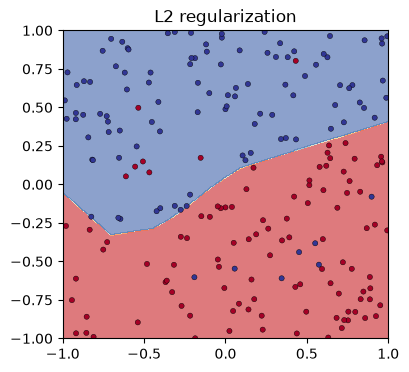

In [ ]:
def compute_cost_with_regularization(A3, Y, params, lambd):
    m = Y.shape[0]
    cross_entropy_cost = compute_cost(A3, Y)
    L2_cost = lambd / (2 * m) * sum((params[f"W{l}"] ** 2).sum() for l in [1, 2, 3])
    return cross_entropy_cost + L2_cost

def backward_propagation_with_regularization(X, Y, params, cache, lambd):
    m = X.shape[0]
    grads = backward_propagation(X, Y, params, cache)     # the usual gradients
    for l in [1, 2, 3]:
        grads[f"dW{l}"] = grads[f"dW{l}"] + lambd / m * params[f"W{l}"]
    return grads

params_L2 = model_reg(reg_train_X, reg_train_Y, lambd=0.7)
results_reg["L2, lambda = 0.7"] = report("L2, lambda = 0.7", logits_by_hand(params_L2))
plot_reg(logits_by_hand(params_L2), "L2 regularization")

Compare with the baseline: the training accuracy should go **down** and the test accuracy **up**, and the boundary should no longer bend around the pockets. Smaller weights give a simpler, smoother function.

`backward_propagation_with_regularization` reuses `backward_propagation` and only adds $\frac{\lambda}{m}\mathbf{W}^{[l]}$: the regularization changes nothing else.

### 2.4 Dropout, by hand
Inverted dropout on the two hidden layers (lecture: "Dropout regularization"). For layer 1, at **every** iteration:
1. draw a mask `D1` of the same shape as `A1`, $(m, n^{[1]})$, with 1 with probability `keep_prob` and 0 otherwise;
2. `A1 = A1 * D1`: shut down the dropped units;
3. `A1 = A1 / keep_prob`: keep the expected value of `A1` unchanged.

In the backward pass, apply the **same** mask and the same scaling to `dA1`. Same for layer 2. No dropout on the input or the output layer.

Cost after iteration 0: 0.7146
Cost after iteration 10000: 0.2032
Cost after iteration 20000: 0.1904
dropout, keep_prob = 0.86: train accuracy 95.3% | test accuracy 94.0%


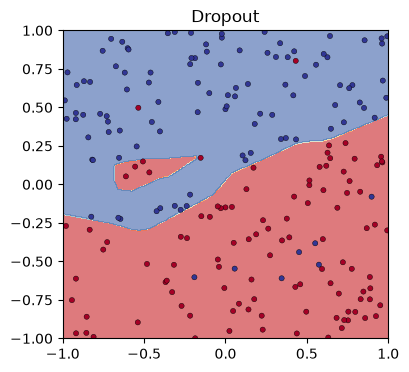

In [ ]:
def forward_propagation_with_dropout(X, params, keep_prob, gen):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    D1 = (torch.rand(A1.shape, generator=gen) < keep_prob).float()    # step 1
    A1 = A1 * D1                                                      # step 2
    A1 = A1 / keep_prob                                               # step 3
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    D2 = (torch.rand(A2.shape, generator=gen) < keep_prob).float()
    A2 = A2 * D2 / keep_prob
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, D1, A1, Z2, D2, A2, Z3, A3)
    return A3, cache

def backward_propagation_with_dropout(X, Y, params, cache, keep_prob):
    m = X.shape[0]
    Z1, D1, A1, Z2, D2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dA2 = dA2 * D2 / keep_prob                 # same mask, same scaling
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dA1 = dA1 * D1 / keep_prob
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

params_drop = model_reg(reg_train_X, reg_train_Y, keep_prob=0.86)
results_reg["dropout, keep_prob = 0.86"] = report("dropout, keep_prob = 0.86", logits_by_hand(params_drop))
plot_reg(logits_by_hand(params_drop), "Dropout")

### 2.5 Using PyTorch
| By hand | PyTorch |
|---|---|
| `compute_cost_with_regularization` and $+\frac{\lambda}{m}\mathbf{W}^{[l]}$ in backprop | `weight_decay=λ/m` in the optimizer |
| masks `D1`, `D2`, divide by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` after each hidden ReLU |
| no dropout at test time | `model.eval()` (and `model.train()` to go back) |

Two details:
- **`p` in `nn.Dropout` is the probability of *dropping* a unit**, so `p = 1 - keep_prob`.
- `weight_decay` applies to every parameter it is given. To regularize only the weights, as in the lecture, give the optimizer two **parameter groups**.

In [ ]:
class RegModel(nn.Module):
    def __init__(self, keep_prob=1.0):
        super().__init__()
        self.layer_1 = nn.Linear(2, 20)
        self.layer_2 = nn.Linear(20, 3)
        self.layer_3 = nn.Linear(3, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=1 - keep_prob)      # p = probability of DROPPING a unit

    def forward(self, x):
        x = self.dropout(self.relu(self.layer_1(x)))
        x = self.dropout(self.relu(self.layer_2(x)))
        return self.layer_3(x)                          # logits

def make_optimizer(model, lr, lambd, m):
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    return torch.optim.SGD([{"params": weights, "weight_decay": lambd / m},
                            {"params": biases, "weight_decay": 0.0}], lr=lr)

print(RegModel(keep_prob=0.86))

RegModel(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.14, inplace=False)
)


**Check 1: `weight_decay` does exactly what our L2 code does.** One step with `weight_decay=λ/m` versus one step with the penalty written in the cost:

In [ ]:
lambd, m = 0.7, reg_train_X.shape[0]
torch.manual_seed(0); model_a = RegModel()
torch.manual_seed(0); model_b = RegModel()

# (a) weight_decay in the optimizer
opt_a = make_optimizer(model_a, lr=0.3, lambd=lambd, m=m)
loss_a = nn.BCEWithLogitsLoss()(model_a(reg_train_X), reg_train_Y)
opt_a.zero_grad(); loss_a.backward(); opt_a.step()

# (b) the L2 penalty written in the cost, plain SGD
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.3)
penalty = lambd / (2 * m) * sum((layer.weight ** 2).sum() for layer in [model_b.layer_1, model_b.layer_2, model_b.layer_3])
loss_b = nn.BCEWithLogitsLoss()(model_b(reg_train_X), reg_train_Y) + penalty
opt_b.zero_grad(); loss_b.backward(); opt_b.step()

diff = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"max difference between the parameters after one step: {diff:.1e}")

max difference between the parameters after one step: 0.0e+00


Identical up to rounding. Note that `loss_a` does **not** contain the penalty: with `weight_decay`, the regularization lives in the update rule, not in the printed loss.

**Check 2: `nn.Dropout` is inverted dropout.** On a tensor of ones, in training mode and in evaluation mode:

In [ ]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("train mode:", drop(torch.ones(10)))
drop.eval()
print("eval mode: ", drop(torch.ones(10)))

train mode: tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval mode:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half of the values are set to 0 and the others are divided by `keep_prob = 0.5`, i.e. multiplied by 2. In evaluation mode, `nn.Dropout` does nothing. This is why the loop calls `model.train()` before the training step and `model.eval()` before testing.

Finally, the three models of this part, trained with the same loop as in Part 1:

PyTorch | no regularization: train accuracy 99.1% | test accuracy 83.5%
PyTorch | L2, lambda = 0.7: train accuracy 91.9% | test accuracy 93.5%
PyTorch | dropout, keep_prob = 0.86: train accuracy 96.7% | test accuracy 88.0%


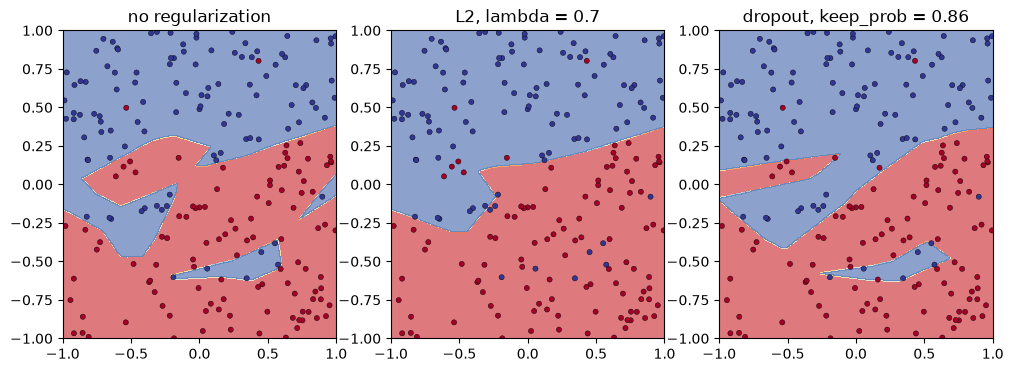

In [ ]:
def train_reg_model(lambd=0.0, keep_prob=1.0, lr=0.3, epochs=30000, seed=3, print_every=None):
    torch.manual_seed(seed)
    model = RegModel(keep_prob).to(device)
    optimizer = make_optimizer(model, lr, lambd, reg_train_X.shape[0])
    return train_and_test(model, nn.BCEWithLogitsLoss(), optimizer, reg_train_X, reg_train_Y,
                          reg_test_X, reg_test_Y, epochs=epochs, print_every=print_every)

results_nn = {}
models_nn = {}
for name, kw in [("no regularization", {}), ("L2, lambda = 0.7", {"lambd": 0.7}), ("dropout, keep_prob = 0.86", {"keep_prob": 0.86})]:
    models_nn[name] = train_reg_model(**kw)
    results_nn[name] = report(f"PyTorch | {name}", models_nn[name])

plt.figure(figsize=(12, 4))
for k, name in enumerate(models_nn):
    plt.subplot(1, 3, k + 1); plt.title(name); plot_decision_boundary(models_nn[name], reg_train_X, reg_train_Y, lim=1.0)
plt.show()

The numbers are not identical to the hand-written version (`nn.Linear` draws its random numbers differently, and the dropout masks differ), but they should lead to the same conclusions.

### 2.6 Conclusions

In [ ]:
print(f"{'model':28s} {'by hand':>18s} {'PyTorch':>18s}")
print(f"{'':28s} {'train':>8s} {'test':>8s}   {'train':>8s} {'test':>8s}")
for name in results_reg:
    (a, b), (c, d) = results_reg[name], results_nn[name]
    print(f"{name:28s} {a:7.1f}% {b:7.1f}%   {c:7.1f}% {d:7.1f}%")

model                                   by hand            PyTorch
                                train     test      train     test
no regularization               96.7%    85.0%      99.1%    83.5%
L2, lambda = 0.7                93.4%    95.0%      91.9%    93.5%
dropout, keep_prob = 0.86       95.3%    94.0%      96.7%    88.0%


**What to remember from Part 2**
- Regularization **lowers the training accuracy** and **raises the test accuracy**: it stops the network from fitting the noise.
- L2 adds $\frac{\lambda}{2m}\sum_l\lVert\mathbf{W}^{[l]}\rVert_F^2$ to the cost and $\frac{\lambda}{m}\mathbf{W}^{[l]}$ to each gradient; in PyTorch, `weight_decay=λ/m`.
- Dropout is used **only during training**, in the forward **and** the backward pass, with the division by `keep_prob`; in PyTorch, `nn.Dropout(p=1 - keep_prob)` with `model.train()` / `model.eval()`.
- $\lambda$ and `keep_prob` are hyperparameters, chosen on a dev set.

---
## ★ Assignment (to submit)

### Exercise 1 · The moons dataset
Make a binary classification dataset with scikit-learn's `make_moons()`: 1000 samples, `noise=0.07`, `random_state=42`. Turn it into PyTorch tensors (`float32`; labels of shape $(m, 1)$) and split it into 80% training and 20% test data with `train_test_split(..., test_size=0.2, random_state=42)`. Plot the training set.

X_train: torch.Size([800, 2])
y_train: torch.Size([800, 1])
X_test: torch.Size([200, 2])
y_test: torch.Size([200, 1])


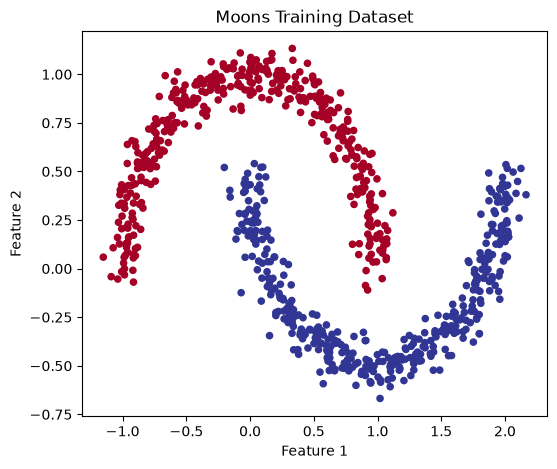

In [ ]:
# Exercise 1

# create the moons dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.07,
    random_state=42
)

# convert the data into PyTorch tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

# split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# print the shapes of the datasets
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# plot the training dataset
plt.figure(figsize=(6, 5))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train.squeeze(),
    cmap=plt.cm.RdYlBu,
    s=20
)

plt.title("Moons Training Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

#### Report: Exercise 1 · The moons dataset

**Purpose**
The goal of this exercise is to prepare the data for the rest of the assignment. The moons dataset has two interlocking half-circles, so it is a non-linear binary classification problem: no straight line can separate the two classes. This is why a neural network with non-linear activations is needed.

**What I did**
- Generated 1000 samples with `make_moons(noise=0.07, random_state=42)`.
- Converted the features to `float32` tensors and the labels to a `float32` tensor of shape `(m, 1)`.
- Split the data 80% / 20% with `train_test_split(test_size=0.2, random_state=42)`.
- Plotted the training set.

**Result**
| Set | Features shape | Labels shape |
|---|---|---|
| Training | (800, 2) | (800, 1) |
| Test | (200, 2) | (200, 1) |

The plot shows two crescent shapes, one for each class, with a small amount of noise.

**Conclusion**
The data is ready: 800 training and 200 test examples with the correct shapes and types. The plot confirms the classes are not linearly separable, so a model with hidden layers and non-linear activations is required.

### Exercise 2 · A model for the moons
Build a model by subclassing `nn.Module`, with non-linear activation functions, capable of fitting the moons. It should output **one logit**. Initialize every `nn.Linear` with **He initialization** and zero biases (Part 1.6). Print the model and its number of parameters.

In [ ]:
# Exercise 2

# build the neural network
class MoonModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(2, 16)
        self.relu_1 = nn.ReLU()

        self.layer_2 = nn.Linear(16, 16)
        self.relu_2 = nn.ReLU()

        self.layer_3 = nn.Linear(16, 1)

    def forward(self, x):
        x = self.layer_1(x)
        x = self.relu_1(x)

        x = self.layer_2(x)
        x = self.relu_2(x)

        x = self.layer_3(x)

        return x


# create the model
model = MoonModel().to(device)

# apply He initialization and zero biases
for layer in model.modules():
    if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal_(layer.weight)
        nn.init.zeros_(layer.bias)

# print the model
print(model)

# count the trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", total_parameters)

MoonModel(
  (layer_1): Linear(in_features=2, out_features=16, bias=True)
  (relu_1): ReLU()
  (layer_2): Linear(in_features=16, out_features=16, bias=True)
  (relu_2): ReLU()
  (layer_3): Linear(in_features=16, out_features=1, bias=True)
)
Total trainable parameters: 337


#### Report: Exercise 2 · A model for the moons

**Purpose**
The goal is to build a neural network by subclassing `nn.Module` that can learn the non-linear moons boundary and output one logit. The exercise also practices He initialization (Part 1.6), which suits ReLU networks.

**What I did**
- Built `MoonModel` with the architecture: `Linear(2→16) → ReLU → Linear(16→16) → ReLU → Linear(16→1)`.
- The ReLU activations give the network the non-linearity it needs.
- The last layer has no activation, so the output is a single logit (the sigmoid is handled by the loss function).
- Applied `nn.init.kaiming_normal_` to every weight and `nn.init.zeros_` to every bias.
- Printed the model and counted its trainable parameters.

**Result**
| Layer | Parameters |
|---|---|
| Linear(2, 16) | 2×16 + 16 = 48 |
| Linear(16, 16) | 16×16 + 16 = 272 |
| Linear(16, 1) | 16×1 + 1 = 17 |
| **Total** | **337** |

**Conclusion**
The model has 337 trainable parameters, which is small but enough for the moons data. He initialization keeps the variance of the activations stable across ReLU layers. Zero biases are fine because the random weights already break the symmetry (as shown in Part 1).

### Exercise 3 · Loss and optimizer
Set up a loss function for binary classification that works with **logits**, and an SGD optimizer (batch gradient descent). Explain in one sentence why `nn.BCEWithLogitsLoss` is preferred to `nn.Sigmoid()` + `nn.BCELoss()`.

In [ ]:
# Exercise 3

# create the loss function
loss_fn = nn.BCEWithLogitsLoss()

# create the optimizer
optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.1
)


The loss function measures how wrong the model's prediction is compared with the correct answer. In binary classification, Binary Cross-Entropy is used to calculate the loss. The optimizer uses gradients to update the model's weights and biases so that the model can learn from its mistakes. I use BCEWithLogitsLoss() because it combines the sigmoid function and binary cross-entropy loss into one operation, making the calculation more numerically stable.

#### Report: Exercise 3 · Loss and optimizer

**Purpose**
The goal is to choose the two components that make learning possible: a loss function that measures how wrong the predictions are, and an optimizer that updates the parameters to reduce that loss.

**What I did**
- Loss function: `nn.BCEWithLogitsLoss()`, the binary cross-entropy for one-logit outputs.
- Optimizer: `torch.optim.SGD(model.parameters(), lr=0.1)`. Because the whole training set is used at each step, this is batch gradient descent.

**Why `BCEWithLogitsLoss` instead of `Sigmoid` + `BCELoss`?**
`BCEWithLogitsLoss` combines the sigmoid and the cross-entropy in one operation using the log-sum-exp trick. This avoids computing `log(0)` when the sigmoid saturates to exactly 0 or 1, so it is more numerically stable.

**Result**
This exercise only sets up the components, so there is no numerical output. Both objects are used in the training loop of Exercise 4.

**Conclusion**
Working with raw logits and `BCEWithLogitsLoss` gives a stable and simple pipeline. The probability is only computed with `torch.sigmoid` when we need predictions.

### Exercise 4 · Training and testing loop
Write a training and testing loop (you may reuse `train_and_test` or write your own) and train the model until it reaches **more than 96% test accuracy**. Print the training and test loss and accuracy every 100 epochs. If you do not reach 96%, change the learning rate, the number of epochs or the number of hidden units, and explain what you changed.

In [ ]:
# Exercise 4

# set the random seed for reproducible results
torch.manual_seed(42)

# create a fresh model
model = MoonModel().to(device)

# apply He initialization and zero biases
for layer in model.modules():
    if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal_(layer.weight)
        nn.init.zeros_(layer.bias)

# create the loss function and optimizer for the fresh model
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.1
)

# set the number of epochs
epochs = 1000

# move the data to the selected device
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

# check accuracy before training
model.eval()

with torch.inference_mode():
    train_logits = model(X_train)
    test_logits = model(X_test)

    train_pred = torch.round(torch.sigmoid(train_logits))
    test_pred = torch.round(torch.sigmoid(test_logits))

    train_acc = accuracy_fn(y_train, train_pred)
    test_acc = accuracy_fn(y_test, test_pred)

print("Before training:")
print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

# training loop
for epoch in range(epochs):

    # set the model to training mode
    model.train()

    # forward pass
    train_logits = model(X_train)

    # calculate the loss
    train_loss = loss_fn(train_logits, y_train)

    # reset gradients
    optimizer.zero_grad()

    # backpropagation
    train_loss.backward()

    # update model parameters
    optimizer.step()

    # print results every 100 epochs
    if epoch % 100 == 0:
        model.eval()

        with torch.inference_mode():
            train_logits = model(X_train)
            test_logits = model(X_test)

            train_loss = loss_fn(train_logits, y_train)
            test_loss = loss_fn(test_logits, y_test)

            train_pred = torch.round(torch.sigmoid(train_logits))
            test_pred = torch.round(torch.sigmoid(test_logits))

            train_acc = accuracy_fn(y_train, train_pred)
            test_acc = accuracy_fn(y_test, test_pred)

        print(
            f"Epoch: {epoch} | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Train Accuracy: {train_acc:.2f}% | "
            f"Test Accuracy: {test_acc:.2f}%"
        )

Before training:
Training Accuracy: 19.12%
Test Accuracy: 19.50%
Epoch: 0 | Train Loss: 0.7268 | Test Loss: 0.7284 | Train Accuracy: 32.38% | Test Accuracy: 31.00%
Epoch: 100 | Train Loss: 0.2465 | Test Loss: 0.2489 | Train Accuracy: 87.62% | Test Accuracy: 86.50%
Epoch: 200 | Train Loss: 0.1884 | Test Loss: 0.1877 | Train Accuracy: 91.88% | Test Accuracy: 91.00%
Epoch: 300 | Train Loss: 0.1382 | Test Loss: 0.1325 | Train Accuracy: 94.00% | Test Accuracy: 94.50%
Epoch: 400 | Train Loss: 0.0893 | Test Loss: 0.0800 | Train Accuracy: 97.38% | Test Accuracy: 98.00%
Epoch: 500 | Train Loss: 0.0568 | Test Loss: 0.0476 | Train Accuracy: 98.88% | Test Accuracy: 99.50%
Epoch: 600 | Train Loss: 0.0382 | Test Loss: 0.0317 | Train Accuracy: 99.38% | Test Accuracy: 99.50%
Epoch: 700 | Train Loss: 0.0276 | Test Loss: 0.0222 | Train Accuracy: 99.88% | Test Accuracy: 100.00%
Epoch: 800 | Train Loss: 0.0209 | Test Loss: 0.0165 | Train Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch: 900 | Train Loss: 

#### Report: Exercise 4 · Training and testing loop

**Purpose**
The goal is to train the moons model and reach more than 96% test accuracy, while monitoring the training and test loss and accuracy to check that the model is learning and generalizing.

**What I did**
- Fixed the seed (`torch.manual_seed(42)`) for reproducibility and created a fresh He-initialized model.
- Used `BCEWithLogitsLoss` and SGD with `lr = 0.1` for 1000 epochs.
- Each epoch followed the standard five steps: forward pass, loss, `zero_grad()`, `backward()`, `optimizer.step()`.
- Every 100 epochs I switched to `model.eval()` and printed the train/test loss and accuracy.

**Result**
| Epoch | Train loss | Test loss | Train acc | Test acc |
|---|---|---|---|---|
| 0 | 0.7268 | 0.7284 | 32.38% | 31.00% |
| 100 | 0.2465 | 0.2489 | 87.62% | 86.50% |
| 300 | 0.1382 | 0.1325 | 94.00% | 94.50% |
| 400 | 0.0893 | 0.0800 | 97.38% | 98.00% |
| 700 | 0.0276 | 0.0222 | 99.88% | 100.00% |
| 900 | 0.0166 | 0.0126 | 100.00% | 100.00% |

The accuracy before training was only about 19%. The 96% target was first passed at around epoch 400, and the model reached 100% on both sets by epoch 800–900.

**Conclusion**
The target was reached with the first configuration, so no changes to the learning rate, epochs or hidden units were needed. The train and test losses decrease together and stay close, which means the model learns the real pattern rather than memorizing, and there is no overfitting. The moons data has little noise, so a small network is enough.

### Exercise 5 · Decision boundaries
Plot the decision boundary of your trained model on the training set and on the test set, side by side, with `plot_decision_boundary`.

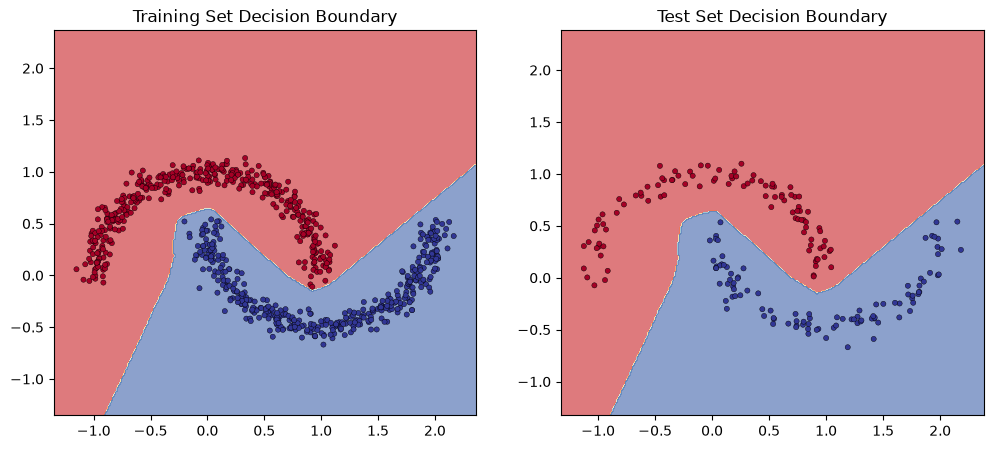

In [ ]:
# Exercise 5

# plot the decision boundary for the training set
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_decision_boundary(model, X_train, y_train)
plt.title("Training Set Decision Boundary")

# plot the decision boundary for the test set
plt.subplot(1, 2, 2)
plot_decision_boundary(model, X_test, y_test)
plt.title("Test Set Decision Boundary")

plt.show()

From the plots, we can see that the model separates the two classes using a curved decision boundary instead of a straight line. The red and blue regions represent the areas where the model predicts each class. Most points are located in the correct regions in both the training and test sets. This shows that the model has learned the pattern of the moons dataset and can classify unseen data correctly. The result is consistent with the 100% test accuracy obtained in Exercise 4.

#### Report: Exercise 5 · Decision boundaries

**Purpose**
The goal is to visualize what the trained model learned by plotting its decision boundary on the training set and the test set side by side. A boundary plot shows the regions where the model predicts each class, which is more informative than accuracy alone.

**What I did**
- Used `plot_decision_boundary` to color the plane by predicted class.
- Created two subplots: one over the training points and one over the test points.

**Result**
In both plots the model separates the two classes with a smooth, curved boundary that follows the shape of the two moons, not a straight line. Almost all points fall in the region of their own class, in both the training and the test sets.

**Conclusion**
The plots confirm the numerical results of Exercise 4 (100% test accuracy). The hidden layers with ReLU let the network create a non-linear boundary, and the same boundary works on unseen test data, so the model generalizes well.

### Exercise 6 · Tanh in pure PyTorch
Write `tanh(z)` using only `torch.exp` and arithmetic: $\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$. Compare it with `torch.tanh` on `torch.linspace(-5, 5, 101)` (print the maximum difference) and plot both.

*Optional:* what happens with your function for $z = 100$? Rewrite it as $\tanh(z) = 2\sigma(2z) - 1$ and explain why this version is safer.

Maximum difference: 1.1920928955078125e-07


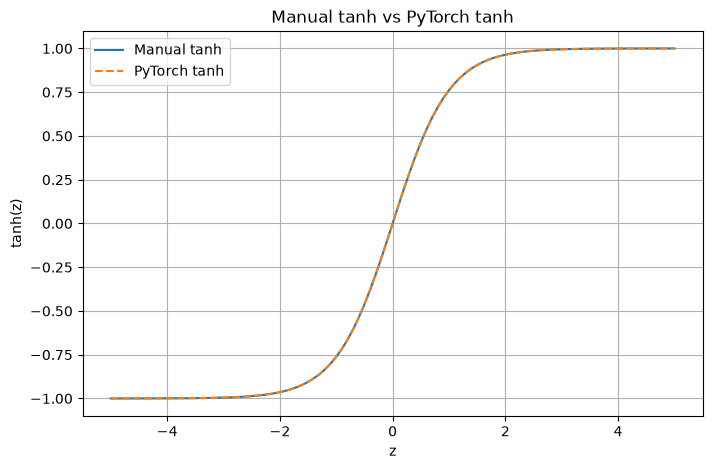

In [ ]:
# Exercise 6: Required part

# create values from -5 to 5
z = torch.linspace(-5, 5, 101)

# calculate tanh using the formula
tanh_manual = (torch.exp(z) - torch.exp(-z)) / (torch.exp(z) + torch.exp(-z))

# calculate tanh using PyTorch
tanh_torch = torch.tanh(z)

# compare the two results
difference = torch.max(torch.abs(tanh_manual - tanh_torch))

print("Maximum difference:", difference.item())

# plot both results
plt.figure(figsize=(8, 5))
plt.plot(z.numpy(), tanh_manual.numpy(), label="Manual tanh")
plt.plot(z.numpy(), tanh_torch.numpy(), "--", label="PyTorch tanh")

plt.title("Manual tanh vs PyTorch tanh")
plt.xlabel("z")
plt.ylabel("tanh(z)")
plt.legend()
plt.grid(True)
plt.show()

The manual formula and PyTorch's torch.tanh() produce almost the same results, as shown by the overlapping lines in the plot. The tanh function approaches 1 when the input is very positive and -1 when the input is very negative. The maximum difference is very small because of floating-point rounding.

In [ ]:
# optional: Test tanh when z = 100

z_large = torch.tensor(100.0)

# calculate tanh using the original formula
tanh_manual = (
    torch.exp(z_large) - torch.exp(-z_large)
) / (
    torch.exp(z_large) + torch.exp(-z_large)
)

print("Manual tanh(100):", tanh_manual)
print("PyTorch tanh(100):", torch.tanh(z_large))

Manual tanh(100): tensor(nan)
PyTorch tanh(100): tensor(1.)


When z = 100, the manual formula produces nan because torch.exp(100) becomes too large to represent, causing an overflow. PyTorch's torch.tanh() handles large values more safely and returns 1. This shows that the original formula works for normal values, but it can fail when the input becomes very large.

In [ ]:
# use the sigmoid formula to calculate tanh(100)
sigmoid_2z = 1 / (1 + torch.exp(-2 * z_large))
tanh_safer = 2 * sigmoid_2z - 1

print("Safer tanh(100):", tanh_safer)
print("PyTorch tanh(100):", torch.tanh(z_large))

Safer tanh(100): tensor(1.)
PyTorch tanh(100): tensor(1.)


The original formula produces nan when z = 100 because the exponential function overflows. The alternative formula uses the sigmoid function and avoids calculating the very large positive exponential. Therefore, it returns 1, matching PyTorch's tanh function.

#### Report: Exercise 6 · Tanh in pure PyTorch

**Purpose**
The goal is to understand the tanh activation by implementing it from its formula, using only `torch.exp` and arithmetic, and to study the numerical problems of a naive implementation.

$$\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$$

**What I did**
- Implemented the formula and compared it with `torch.tanh` on `torch.linspace(-5, 5, 101)`.
- Printed the maximum difference and plotted both curves.
- Optional part: tested `z = 100`, then rewrote the function as $\tanh(z) = 2\sigma(2z) - 1$.

**Result**
| Test | Manual formula | PyTorch / safer version |
|---|---|---|
| Max difference on [-5, 5] | 1.19 × 10⁻⁷ | (reference) |
| tanh(100) | `nan` | `torch.tanh` = 1.0 |
| tanh(100) with $2\sigma(2z)-1$ | – | 1.0 |

The two curves overlap completely. The function is S-shaped, approaching -1 for very negative inputs and +1 for very positive inputs.

**Explanation of the `nan`**
For `z = 100`, `torch.exp(100)` overflows in `float32` and becomes `inf`. The formula then computes `inf / inf`, which gives `nan`. The sigmoid version only computes `exp(-2z)`, which becomes a harmless value close to 0, so the result is correctly 1.

**Conclusion**
The manual implementation is correct for normal values (the difference is only floating-point rounding, about 10⁻⁷). However, the naive formula is numerically unsafe for large inputs. This is why built-in functions such as `torch.tanh`, or a rewritten stable formula, should be used in real code.

### Exercise 7 · A multi-class problem: spirals
Create the 3-class spiral dataset of CS231n with the code below (300 points), turn it into tensors (`X` as `float32`, `y` as `long` of shape $(m,)$), and split it 80/20 with `random_state=42`.

Then:
- build a model capable of fitting the data; it outputs **3 logits** (one per class);
- use `nn.CrossEntropyLoss()` (softmax + cross-entropy, Lecture 2) and an optimizer (optional extension: `torch.optim.Adam`; you may have to try several learning rates);
- write a training and testing loop for the multi-class case (predicted class = `argmax` of the logits) and reach **more than 95% test accuracy**;
- plot the decision boundaries on the training and test sets with `plot_decision_boundary` (it handles several classes).

```python
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()
```

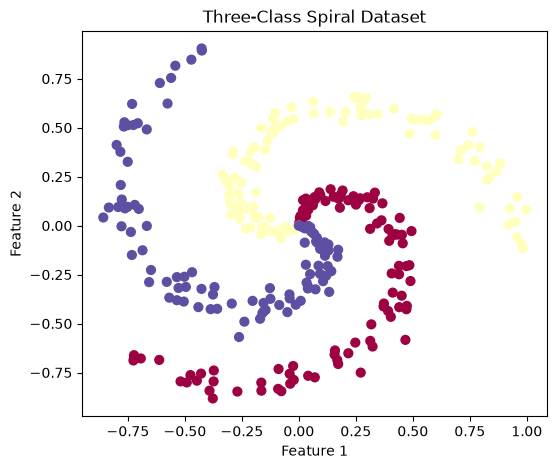

X_train: torch.Size([240, 2])
y_train: torch.Size([240])
X_test: torch.Size([60, 2])
y_test: torch.Size([60])
Classes: tensor([0, 1, 2])
SpiralModel(
  (layer1): Linear(in_features=2, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=16, bias=True)
  (layer3): Linear(in_features=16, out_features=3, bias=True)
)
Epoch: 0 | Train loss: 1.1212 | Test loss: 1.1216 | Train accuracy: 33.33% | Test accuracy: 33.33%
Epoch: 100 | Train loss: 0.1140 | Test loss: 0.1376 | Train accuracy: 97.92% | Test accuracy: 95.00%
Epoch: 200 | Train loss: 0.0300 | Test loss: 0.0716 | Train accuracy: 99.58% | Test accuracy: 96.67%
Epoch: 300 | Train loss: 0.0175 | Test loss: 0.0671 | Train accuracy: 99.58% | Test accuracy: 98.33%
Epoch: 400 | Train loss: 0.0127 | Test loss: 0.0672 | Train accuracy: 99.58% | Test accuracy: 98.33%
Epoch: 500 | Train loss: 0.0104 | Test loss: 0.0690 | Train accuracy: 99.58% | Test accuracy: 98.33%
Epoch: 600 | Train loss: 0.0091 | Test loss: 0.0709 | Tra

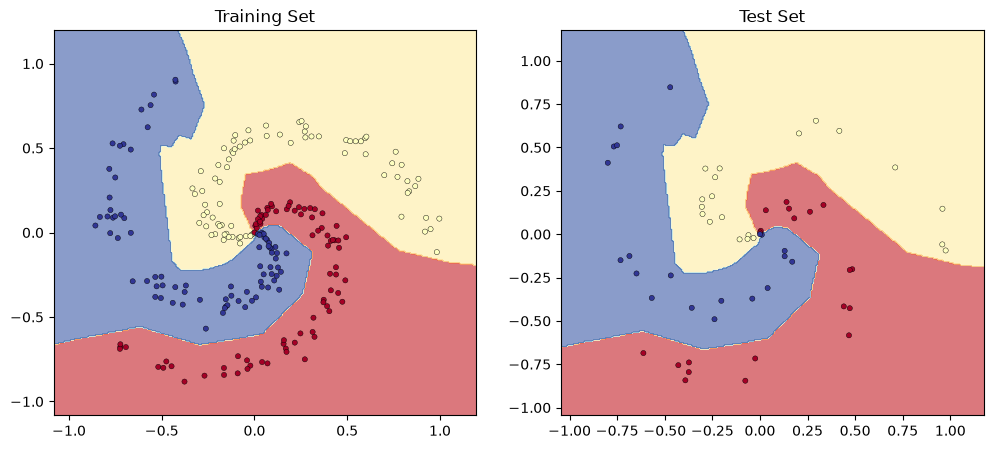

In [ ]:
# Exercise 7: data

# set random seeds so the results are reproducible
np.random.seed(42)
torch.manual_seed(42)

# Create the spiral dataset from CS231n
N = 100  # Number of points per class
D = 2    # Number of features
K = 3    # Number of classes

X = np.zeros((N * K, D))
y = np.zeros(N * K, dtype="uint8")

for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2

    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j

# plot the original spiral dataset
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.title("Three-Class Spiral Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


# convert the data into PyTorch tensors
# use clone().detach() to avoid warnings when X or y are already tensors
if isinstance(X, torch.Tensor):
    X = X.clone().detach().to(dtype=torch.float32)
else:
    X = torch.tensor(X, dtype=torch.float32)

if isinstance(y, torch.Tensor):
    y = y.clone().detach().to(dtype=torch.long).reshape(-1)
else:
    y = torch.tensor(y, dtype=torch.long).reshape(-1)


# split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42,
stratify=y
)

# print the shapes of the datasets
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Classes:", torch.unique(y))


# build model
class SpiralModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(2, 16)
        self.layer2 = nn.Linear(16, 16)
        self.layer3 = nn.Linear(16, 3)

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        x = self.layer3(x)
        return x


model = SpiralModel().to(device)

print(model)


# set up the loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)


# training and testing loop
epochs = 1000

for epoch in range(epochs):

    # training
    model.train()

    y_logits = model(X_train)
    loss = loss_fn(y_logits, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # print results every 100 epochs
    if epoch % 100 == 0:
        model.eval()

        with torch.inference_mode():
            train_logits = model(X_train)
            test_logits = model(X_test)

            train_loss = loss_fn(train_logits, y_train)
            test_loss = loss_fn(test_logits, y_test)

            train_pred = train_logits.argmax(dim=1)
            test_pred = test_logits.argmax(dim=1)

            train_acc = (train_pred == y_train).float().mean() * 100
            test_acc = (test_pred == y_test).float().mean() * 100

        print(
            f"Epoch: {epoch} | "
            f"Train loss: {train_loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f} | "
            f"Train accuracy: {train_acc.item():.2f}% | "
            f"Test accuracy: {test_acc.item():.2f}%"
        )


# plot the decision boundaries
model.eval()

plt.figure(figsize=(12, 5))

# training set
plt.subplot(1, 2, 1)
plot_decision_boundary(model, X_train, y_train)
plt.title("Training Set")

# test set
plt.subplot(1, 2, 2)
plot_decision_boundary(model, X_test, y_test)
plt.title("Test Set")

plt.show()

#### Report: Exercise 7 · A multi-class problem: spirals

**Purpose**
The goal is to move from binary to multi-class classification. The 3-class spiral dataset (CS231n) is highly non-linear, with three intertwined arms, and it requires a model with 3 outputs, a softmax-based loss, and `argmax` for predictions.

**What I did**
- Generated 300 points (100 per class) and split them 80/20 (240 train / 60 test) with `random_state=42` and `stratify=y`, so each class is equally represented in both sets.
- Labels `y` are `long` tensors of shape `(m,)`, as `CrossEntropyLoss` requires.
- Built `SpiralModel`: `Linear(2→16) → ReLU → Linear(16→16) → ReLU → Linear(16→3)`, which outputs 3 logits.
- Used `nn.CrossEntropyLoss()` (softmax + cross-entropy) and the `Adam` optimizer with `lr = 0.01` for 1000 epochs.
- The predicted class is `argmax` of the logits. I plotted the decision boundaries on both sets.

**Result**
| Epoch | Train loss | Test loss | Train acc | Test acc |
|---|---|---|---|---|
| 0 | 1.1212 | 1.1216 | 33.33% | 33.33% |
| 100 | 0.1140 | 0.1376 | 97.92% | 95.00% |
| 300 | 0.0175 | 0.0671 | 99.58% | 98.33% |
| 900 | 0.0074 | 0.0779 | 99.58% | 98.33% |

The starting accuracy of 33.33% equals random guessing for 3 classes. The model passed the 95% target by epoch 100 and ended at 98.33% test accuracy.

**Conclusion**
The target of more than 95% test accuracy was reached. The decision-boundary plots show three curved, spiral-shaped regions that follow the data. Adam converged much faster than plain SGD would, which is useful for this harder problem. After epoch 300 the test loss slowly rises (0.067 → 0.078) while the training loss keeps falling, which is an early sign of overfitting. This motivates Exercise 8.

### Exercise 8 · Regularization on the spirals (TP3)
Train a **much larger** spiral model (for example two hidden layers of 128 units) for long enough that it overfits: training accuracy near 100%, and a visible gap with the test accuracy. Then train the same model with
- **L2 regularization** (`weight_decay` on the weights only, as in Part 2.5), and
- **dropout** (`nn.Dropout`),

keeping everything else equal. Report the training and test accuracy of the three models in a small table, plot the three decision boundaries, and answer in a markdown cell: which model would you choose, and why? Which set should be used to choose `weight_decay` and the dropout rate in a real project?

In [ ]:
# Exercise 8

# set random seeds
np.random.seed(42)
torch.manual_seed(42)


# build a larger model
class LargeSpiralModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(2, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, 3)

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        x = self.layer3(x)
        return x


# set up the loss function
loss_fn = nn.CrossEntropyLoss()


# create the baseline model
baseline_model = LargeSpiralModel().to(device)

print("Baseline Model")
print(baseline_model)

baseline_optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.01
)


# train the baseline model
epochs = 3000

for epoch in range(epochs):

    baseline_model.train()

    y_logits = baseline_model(X_train)
    loss = loss_fn(y_logits, y_train)

    baseline_optimizer.zero_grad()
    loss.backward()
    baseline_optimizer.step()

    # print results every 500 epochs
    if epoch % 500 == 0:
        baseline_model.eval()

        with torch.inference_mode():
            train_logits = baseline_model(X_train)
            test_logits = baseline_model(X_test)

            train_loss = loss_fn(train_logits, y_train)
            test_loss = loss_fn(test_logits, y_test)

            train_pred = train_logits.argmax(dim=1)
            test_pred = test_logits.argmax(dim=1)

            train_acc = (train_pred == y_train).float().mean().item() * 100
            test_acc = (test_pred == y_test).float().mean().item() * 100

        print(
            f"Epoch: {epoch} | "
            f"Train loss: {train_loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f} | "
            f"Train accuracy: {train_acc:.2f}% | "
            f"Test accuracy: {test_acc:.2f}%"
        )


# calculate final baseline accuracy
baseline_model.eval()

with torch.inference_mode():
    train_logits = baseline_model(X_train)
    test_logits = baseline_model(X_test)

    train_pred = train_logits.argmax(dim=1)
    test_pred = test_logits.argmax(dim=1)

    baseline_train_acc = (
        (train_pred == y_train).float().mean().item() * 100
    )

    baseline_test_acc = (
        (test_pred == y_test).float().mean().item() * 100
    )

print("\nBaseline Results")
print(f"Training accuracy: {baseline_train_acc:.2f}%")
print(f"Test accuracy: {baseline_test_acc:.2f}%")


# create a function to train and evaluate a model
def train_model(model, optimizer, epochs=3000):

    for epoch in range(epochs):

        # training
        model.train()

        y_logits = model(X_train)
        loss = loss_fn(y_logits, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # evaluate the model
    model.eval()

    with torch.inference_mode():
        train_logits = model(X_train)
        test_logits = model(X_test)

        train_pred = train_logits.argmax(dim=1)
        test_pred = test_logits.argmax(dim=1)

        train_acc = (
            (train_pred == y_train).float().mean().item() * 100
        )

        test_acc = (
            (test_pred == y_test).float().mean().item() * 100
        )

    print(f"Training accuracy: {train_acc:.2f}%")
    print(f"Test accuracy: {test_acc:.2f}%")

    return train_acc, test_acc


# create the L2 regularization model
torch.manual_seed(42)

l2_model = LargeSpiralModel().to(device)

# apply L2 regularization to weights only
l2_optimizer = torch.optim.Adam(
    [
        {
            "params": [
                l2_model.layer1.weight,
                l2_model.layer2.weight,
                l2_model.layer3.weight
            ],
            "weight_decay": 0.01
        },
        {
            "params": [
                l2_model.layer1.bias,
                l2_model.layer2.bias,
                l2_model.layer3.bias
            ],
            "weight_decay": 0.0
        }
    ],
    lr=0.01
)

print("\nL2 Regularization Model")

l2_train_acc, l2_test_acc = train_model(
    l2_model,
    l2_optimizer,
    epochs=3000
)


# build the dropout model
class DropoutSpiralModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(2, 128)
        self.dropout1 = nn.Dropout(p=0.3)

        self.layer2 = nn.Linear(128, 128)
        self.dropout2 = nn.Dropout(p=0.3)

        self.layer3 = nn.Linear(128, 3)

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = self.dropout1(x)

        x = torch.relu(self.layer2(x))
        x = self.dropout2(x)

        x = self.layer3(x)
        return x


# create and train the dropout model
torch.manual_seed(42)

dropout_model = DropoutSpiralModel().to(device)

dropout_optimizer = torch.optim.Adam(
    dropout_model.parameters(),
    lr=0.01
)

print("\nDropout Model")

dropout_train_acc, dropout_test_acc = train_model(
    dropout_model,
    dropout_optimizer,
    epochs=3000
)


# compare all three models
print("\nComparison of All Three Models")

print(
    f"Baseline - Training: {baseline_train_acc:.2f}% | "
    f"Test: {baseline_test_acc:.2f}%"
)

print(
    f"L2 Regularization - Training: {l2_train_acc:.2f}% | "
    f"Test: {l2_test_acc:.2f}%"
)

print(
    f"Dropout - Training: {dropout_train_acc:.2f}% | "
    f"Test: {dropout_test_acc:.2f}%"
)


Baseline Model
LargeSpiralModel(
  (layer1): Linear(in_features=2, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=3, bias=True)
)
Epoch: 0 | Train loss: 0.9969 | Test loss: 1.0047 | Train accuracy: 59.58% | Test accuracy: 51.67%
Epoch: 500 | Train loss: 0.0065 | Test loss: 0.0951 | Train accuracy: 99.58% | Test accuracy: 96.67%
Epoch: 1000 | Train loss: 0.0060 | Test loss: 0.1124 | Train accuracy: 99.58% | Test accuracy: 96.67%
Epoch: 1500 | Train loss: 0.0059 | Test loss: 0.1246 | Train accuracy: 99.58% | Test accuracy: 96.67%
Epoch: 2000 | Train loss: 0.0058 | Test loss: 0.1372 | Train accuracy: 99.58% | Test accuracy: 96.67%
Epoch: 2500 | Train loss: 0.0058 | Test loss: 0.1453 | Train accuracy: 99.58% | Test accuracy: 96.67%

Baseline Results
Training accuracy: 99.58%
Test accuracy: 96.67%

L2 Regularization Model
Training accuracy: 98.33%
Test accuracy: 96.67%

Dropout Model
Training acc

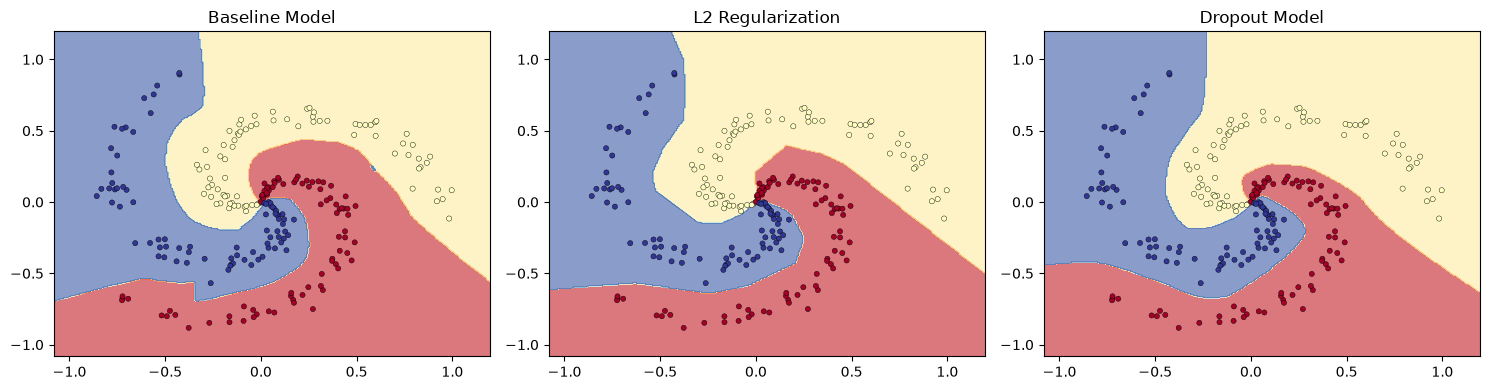

In [ ]:
# plot decision boundaries for all three models

plt.figure(figsize=(15, 4))

# Baseline model
plt.subplot(1, 3, 1)
plot_decision_boundary(baseline_model, X_train, y_train)
plt.title("Baseline Model")

# L2 regularization model
plt.subplot(1, 3, 2)
plot_decision_boundary(l2_model, X_train, y_train)
plt.title("L2 Regularization")

# Dropout model
plt.subplot(1, 3, 3)
plot_decision_boundary(dropout_model, X_train, y_train)
plt.title("Dropout Model")

plt.tight_layout()
plt.show()

### Conclusion
The baseline model achieved 99.58% training accuracy and 96.67% test accuracy. The L2 regularization model achieved 98.33% training accuracy and 96.67% test accuracy. The dropout model achieved 99.58% training accuracy and 98.33% test accuracy.

Based on these results, I would choose the dropout model because it achieved the highest test accuracy. The baseline and L2 models had the same test accuracy, while L2 regularization reduced the training accuracy. The dropout model performed best on the test set in this experiment.

In a real project, I would use a validation set to choose the `weight_decay` value and dropout rate. I would keep the test set separate and use it for the final evaluation of the model.

#### Report: Exercise 8 · Regularization on the spirals

**Purpose**
The goal is to study overfitting and how regularization reduces it. A much larger model is trained on the small spiral dataset (240 training points), then the same model is trained with L2 regularization and with dropout, keeping everything else equal, to compare their generalization.

**What I did**
- Built a larger model with two hidden layers of 128 units (`2 → 128 → 128 → 3`), trained for 3000 epochs with Adam (`lr = 0.01`).
- **Baseline:** no regularization.
- **L2:** `weight_decay = 0.01` applied to the weights only, using two parameter groups (biases have `weight_decay = 0`).
- **Dropout:** `nn.Dropout(p=0.3)` after each hidden ReLU layer, with `model.train()` / `model.eval()` switching the behaviour.
- Compared the three models and plotted their decision boundaries.

**Result**
| Model | Training accuracy | Test accuracy |
|---|---|---|
| Baseline (no regularization) | 99.58% | 96.67% |
| L2 (`weight_decay` = 0.01) | 98.33% | 96.67% |
| Dropout (p = 0.3) | 99.58% | 98.33% |

The baseline reached 99.58% training accuracy within 500 epochs. Its test loss then rose from 0.095 to 0.145 while its training loss stayed flat near 0.006, which is the typical sign of overfitting. L2 lowered the training accuracy slightly (as expected, since it limits the weights), and dropout gave the best test accuracy.

**Which model would I choose, and why?**
I would choose the **dropout model**, because it had the highest test accuracy (98.33%). L2 only matched the baseline on the test set, and its training accuracy dropped. However, the test set has only 60 points, so one point is worth 1.67%. The difference between dropout and the other models is therefore just one test example, and it should not be treated as strong proof. A fairer comparison would use several random seeds or cross-validation.

**Which set should be used to choose `weight_decay` and the dropout rate?**
In a real project, these hyperparameters should be chosen on a **validation (dev) set**. The test set must stay untouched until the very end and be used only once for the final evaluation. Otherwise the test score would be optimistic, because the hyperparameters would have been tuned to it.

**Conclusion**
Even with a large model, regularization improved or at least kept generalization, and it reduced the gap between training and test performance. Dropout worked best here, while L2 gave a smoother, more constrained model. Both are hyperparameters that must be tuned on a validation set.